In [54]:
from IPython.display import Image
from ipywidgets import interact, SelectionSlider
from lib.utils import *

## 2. Generative Adversarial Networks - 35 points

Please review Lecture 11 for the notation and the setup in this exercise, and the supplementary lecture on deep learning with PyTorch for the coding tricks.

After the LLM boom, Kocho realized his coding skills have become useless and he wants to make a career change. As Kocho cannot dance, he had to drop his dream of becoming a tiktok influencer. Kocho realized a lot of young people was creating clothing brands, and in his poor understanding of supply and demand, he thought this meant there was a high demand. But Kocho only knows how to code! How is he supposed to design clothes? Apparently there is this kind of AI called Wasserstein Generative Adversarial Networks (WGANs) that can do it for him. 

Your goal in this notebook is to fill in the gaps in Kocho's knowledge on how to get his WGAN to work. Specifically, both his generator neural network $h_\mathbf{x}$ (that outputs fake images) and dual variable neural network $d_\mathbf{y}$ (that scores images) are defined as convolutional neural networks in the following function classes:

\begin{equation}
\begin{aligned}
    \mathcal{H} & :=\{h: \mathbb{R}^{D} \to [0, 1]^{28 \times 28}| h_{\mathbf{x}}(\omega)=\sigma(c^T(\texttt{gelu}(c^T(\texttt{gelu}(c^T(\texttt{gelu}(c^T(\omega; X_1, \mu_1));X_2, \mu_2));X_3,\mu_3));X_4, \mu_4))\}, \\
    \qquad \mathcal{D} & := \{d: [0, 1]^{28 \times 28} \to \mathbb{R} | d_{\mathbf{y}}({\bf a})= Y_3 \cdot \texttt{leakyrelu}(c(\texttt{leakyrelu}(c({\bf a};Y_1,\nu_1));Y_2,\nu_2)) + \nu_3
    \},
\end{aligned}
\end{equation}

where $\mathbf{x} =[\mu_1;\mu_2;\mu_3;\mu_4;{X_1};{X_2};{X_3};X_4]$ are the "generator" parameters, $\mathbf{y} =[\nu_1;\nu_2;\nu_3;{Y_1};{Y_2}; Y_3] $ are the
"dual" or the "discriminator" parameters, $c$ and $c^T$ are the learnable 2d convolution and transposed convolution operators, $D$ is the noise dimension (a hyperparameter) and $\sigma$ is the sigmoid function.

In the following cells, you will implement the two neural networks as well as the spectral normalization ([Myato 2018](https://arxiv.org/abs/1802.05957)) and weight clipping ([Petzka 2017](https://arxiv.org/abs/1709.08894)) methods for enforcing a Lipschitz constraint on the dual variable.

**(1)** (3 points) Implement the convolutional neural network for the generator below. See `torch.nn.Sequential` docs for a start.

**Hints:**

* You may include normalization layers (e.g. nn.BatchNorm2d) after transposed convolutional layers to help stabilize training.

* Consider using feature map dimensions such as 256 → 128 → 64 for successive layers (you may adjust if needed).

* When selecting kernel_size, stride, and padding, ensure that the layer dimensions are consistent. Use the standard convolution formula:

\begin{equation}
\begin{aligned}
    O = ( \frac{I+2P-K}{S} ) + 1
\end{aligned}
\end{equation}

where
 * O: output size
 * I: input size
 * P: padding
 * K: kernel size
 * S: stride

In [55]:
class Generator(nn.Module):

    def __init__(self, noise_dim=100):
        super().__init__()

        # Spatial sizes: 1 -> 3 -> 7 -> 14 -> 28
        # ConvTranspose output: O = (I - 1) * S - 2P + K
        self.inner = nn.Sequential(
            # (B, noise_dim, 1, 1) -> (B, 256, 3, 3)   : (1-1)*1 - 0 + 3 = 3
            nn.ConvTranspose2d(noise_dim, 256, kernel_size=3, stride=1, padding=0),
            nn.BatchNorm2d(256),
            nn.GELU(),
            # (B, 256, 3, 3) -> (B, 128, 7, 7)         : (3-1)*2 - 0 + 3 = 7
            nn.ConvTranspose2d(256, 128, kernel_size=3, stride=2, padding=0),
            nn.BatchNorm2d(128),
            nn.GELU(),
            # (B, 128, 7, 7) -> (B, 64, 14, 14)        : (7-1)*2 - 2 + 4 = 14
            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(64),
            nn.GELU(),
            # (B, 64, 14, 14) -> (B, 1, 28, 28)        : (14-1)*2 - 2 + 4 = 28
            nn.ConvTranspose2d(64, 1, kernel_size=4, stride=2, padding=1),
            nn.Sigmoid(),  # output in [0, 1]
        )

    def forward(self, omega):
        return self.inner(omega)

In [56]:
# Sanity check: shapes at each layer and output range
_g = Generator(noise_dim=100)
_x = torch.randn(8, 100, 1, 1)  # same shape used by lib/utils.train
print("input:", tuple(_x.shape))
for layer in _g.inner:
    _x = layer(_x)
    if isinstance(layer, nn.ConvTranspose2d):
        print(f"{layer.__class__.__name__:>16} ->", tuple(_x.shape))
assert _x.shape == (8, 1, 28, 28)
print(f"output range: [{_x.min().item():.4f}, {_x.max().item():.4f}]")
print("# params:", sum(p.numel() for p in _g.parameters()))

input: (8, 100, 1, 1)
 ConvTranspose2d -> (8, 256, 3, 3)
 ConvTranspose2d -> (8, 128, 7, 7)
 ConvTranspose2d -> (8, 64, 14, 14)
 ConvTranspose2d -> (8, 1, 28, 28)
output range: [0.0014, 0.9966]
# params: 658753


A critical aspect of WGANs is Lipschitzness of the discriminator. We know that the Lipschitz constant of a linear layer in the form $\mathbf{b} = \mathbf{W}\mathbf{a}$ is given by $\left|\left|\mathbf{W}\right|\right|_{2}$. We also know that a 2D circular convolution with kernel $\mathbf{K} \in \mathbb{R}^{k\times k}$ can be represented as a linear transformation of the flattened image, i.e., $\text{flat}(\mathbf{b}) = \mathbf{W}_{\mathbf{K}}\text{flat}(\mathbf{a})$ ([Sedghi 2019](https://arxiv.org/abs/1805.10408)). But what happens if we increase the `stride` parameter of the convolutional operator? The stride of the convolutional layer just results in a downsamplig of the output. In this exercise we will compute the Lipschitz constant of convolutional layers with `stride=2`.

**Example**
The 1D circular convolution $\mathbf{b} = \mathbf{k} \circledast \mathbf{a}$ with the kernel $\mathbf{k} = [k_1, k_2, k_3] \in \mathbb{R}^{3}$ and $\mathbf{a} \in \mathbb{R}^{d}, \mathbf{b} \in \mathbb{R}^{d}$ can be written as:

$$
    \mathbf{b} = \left(\begin{matrix}
        k_2 & k_3 & 0 & \cdots & & 0 & k_1\\
        k_1 & k_2 & k_3 & 0 & \cdots & & 0 \\
        0 & k_1 & k_2 & k_3 & 0 & \cdots & 0 \\
        &&&\vdots \\
        0 & \cdots &  & 0 & k_1 & k_2 & k_3 \\
        k_3 & \cdots &  & 0 & 0 & k_1 & k_2 \\
    \end{matrix}\right)\mathbf{a} = \mathbf{W}_{\mathbf{k}}\mathbf{a}\,,
$$
where $\mathbf{W}_{\mathbf{k}} \in \mathbb{R}^{d\times d}$. With `stride=2`, the operation results in:
$$
    \hat{\mathbf{b}} = \left(\begin{matrix}
        k_2 & k_3 & 0 & \cdots & & & & 0 & k_1\\
        0 & k_1 & k_2 & k_3 & 0 & \cdots & & & 0 \\
        0 & 0 & 0 & k_1 & k_2 & k_3 & 0 & \cdots & 0 \\
        &&&&\vdots \\
        0 & \cdots & & & & 0 & k_1 & k_2 & k_3 \\
        k_3 & \cdots & & & & 0 & 0 & k_1 & k_2 \\
    \end{matrix}\right)\mathbf{a} = \hat{\mathbf{W}}_{\mathbf{k}}\mathbf{a}
$$
where $\hat{\mathbf{W}}_{\mathbf{k}} \in \mathbb{R}^{d/2\times d}$ and $d$ must be divisible by $2$.

**(2)** (2 points) What is the Lipschitz constant of the convolutional layer with `stride=2` from the previous example?

**Hint** Try finding a matrix $\mathbf{S}\in \mathbb{R}^{d/2 \times d}$ so that $\hat{\mathbf{W}}_{\mathbf{k}} = \mathbf{S}\mathbf{W}_{\mathbf{k}}$, what is $\mathbf{S}\mathbf{S}^{\top}$?



**Answer (2).**

The strided convolution is the full (stride-1) convolution followed by keeping every other output, i.e. $\hat{\mathbf{W}}_{\mathbf{k}} = \mathbf{S}\mathbf{W}_{\mathbf{k}}$ with the row-selection matrix
$$
\mathbf{S} = \begin{pmatrix}
1 & 0 & 0 & 0 & \cdots & 0 & 0\\
0 & 0 & 1 & 0 & \cdots & 0 & 0\\
  &   &   & \vdots &   &   &  \\
0 & 0 & 0 & 0 & \cdots & 1 & 0
\end{pmatrix} \in \mathbb{R}^{d/2 \times d}, \qquad S_{ij} = \mathbb{1}[\,j = 2i-1\,].
$$
Each row of $\mathbf{S}$ has a single $1$ and no two rows share a column, hence
$$
\mathbf{S}\mathbf{S}^\top = \mathbf{I}_{d/2} \quad\Longrightarrow\quad \|\mathbf{S}\|_2 = \sqrt{\lambda_{\max}(\mathbf{S}\mathbf{S}^\top)} = 1 .
$$
The Lipschitz constant of the linear map $\mathbf{a} \mapsto \hat{\mathbf{W}}_{\mathbf{k}}\mathbf{a}$ is its spectral norm, and by submultiplicativity
$$
L = \|\hat{\mathbf{W}}_{\mathbf{k}}\|_2 = \|\mathbf{S}\mathbf{W}_{\mathbf{k}}\|_2 \le \|\mathbf{S}\|_2\,\|\mathbf{W}_{\mathbf{k}}\|_2 = \|\mathbf{W}_{\mathbf{k}}\|_2 = \max_{j=0,\dots,d-1} |\lambda_j|,
$$
where, since $\mathbf{W}_{\mathbf{k}}$ is circulant (hence normal), its singular values are the moduli of its eigenvalues, i.e. of the DFT of the zero-padded kernel:
$$
\lambda_j = k_2 + k_3\, e^{-2\pi \mathrm{i}\, j/d} + k_1\, e^{2\pi \mathrm{i}\, j/d}, \qquad j = 0,\dots,d-1 .
$$
So **striding never increases the Lipschitz constant**: the stride-2 layer is at most as Lipschitz as the stride-1 one, and $\|\mathbf{W}_{\mathbf{k}}\|_2 = \max_j |\mathrm{DFT}_d(\mathbf{k})_j|$ is a valid (and cheap) upper bound to use for spectral normalization.

*Exact value.* $\hat{\mathbf{W}}_{\mathbf{k}}\hat{\mathbf{W}}_{\mathbf{k}}^\top = \mathbf{S}\,(\mathbf{W}_{\mathbf{k}}\mathbf{W}_{\mathbf{k}}^\top)\,\mathbf{S}^\top$ keeps the even-indexed entries of a circulant matrix, which is again circulant (of size $d/2$). Its eigenvalues are obtained by aliasing the eigenvalues $|\lambda_j|^2$ of $\mathbf{W}_{\mathbf{k}}\mathbf{W}_{\mathbf{k}}^\top$:
$$
L = \|\hat{\mathbf{W}}_{\mathbf{k}}\|_2 = \sqrt{\max_{m=0,\dots,d/2-1} \frac{|\lambda_m|^2 + |\lambda_{m+d/2}|^2}{2}} \;\in\; \left[\tfrac{1}{\sqrt{2}}\|\mathbf{W}_{\mathbf{k}}\|_2,\; \|\mathbf{W}_{\mathbf{k}}\|_2\right],
$$
consistent with the bound above (equality with $\|\mathbf{W}_{\mathbf{k}}\|_2$ holds when the largest $|\lambda_j|$ is attained at both $j$ and $j+d/2$).

Now that we know how the stride affects the Lipschitz constant, we are ready to perform `spectral_normalization` and `weight_clipping`. You can use feature map dimensions 64 → 128.

**(3)** (9 points) Implement below the convolutional network with circular padding for the discriminator and implement the spectral normalization and weight clipping methods. Use the findings from Theorem 6 in [Sedghi 2019](https://arxiv.org/abs/1805.10408) regarding the singular values of the linear form of a convolutional layer and check the pseudocode in the summary of results. Note that `torch.fft.fft(W,dim=-1)` computes the Discrete Fourier Transform along the last dimension of the tensor `W`. Be careful with the input image size at each layer! Also note that since the we are interested in the maximum singular value, we can simply use `torch.linalg.norm(..., ord=2)` instead of computing the SVD.

**Remark:** The `spectral_normalization` and `weight_clipping` methods do not need to return a value. They should modify the appropriate parameters in $\mathbf{y}$ of the dual network $d_{\mathbf{y}}$ in place. Make sure to distinguish between convolutional and linear layers when performing spectral normalization. Remember not to track gradients in those operations. 

In [57]:
class DualVariable(nn.Module):

    def __init__(self, c=1e-2, mode="spectral_norm"):
        super().__init__()
        self.c = c
        self.mode = mode

        # Spatial sizes: 28 -> 14 -> 7, circular padding.  Conv output: O = (I + 2P - K) / S + 1
        self.inner = nn.Sequential(
            # (B, 1, 28, 28) -> (B, 64, 14, 14)   : (28 + 2 - 4) / 2 + 1 = 14
            nn.Conv2d(1, 64, kernel_size=4, stride=2, padding=1, padding_mode="circular"),
            nn.LeakyReLU(0.2),
            # (B, 64, 14, 14) -> (B, 128, 7, 7)   : (14 + 2 - 4) / 2 + 1 = 7
            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1, padding_mode="circular"),
            nn.LeakyReLU(0.2),
            # (B, 128, 7, 7) -> (B, 128*7*7) -> (B, 1)
            nn.Flatten(),
            nn.Linear(128 * 7 * 7, 1),
        )
        self.input_size = 28  # spatial size of the images fed to the first layer

    def forward(self, x):
        return self.inner(x)

    def enforce_lipschitz(self):
        if self.mode == "spectral_norm":
            self.spectral_normalisation()
        elif self.mode == "weight_clip":
            self.weight_clipping()
        else:
            raise ValueError("Invalid enforce_lipschitz mode")

    @staticmethod
    def conv_spectral_norm(weight, n):
        """
        Largest singular value of the linear form of the circular convolution with kernel
        `weight` of shape (out_c, in_c, k, k) acting on n x n inputs (Sedghi et al. 2019, Thm 6).
        It is computed for stride 1: by part (2) the stride can only decrease the spectral
        norm, so this is a valid upper bound for the strided layer.
        """
        # 2D DFT of each (o, c) kernel, zero-padded to the n x n input size
        transforms = torch.fft.fft2(weight, s=(n, n), dim=(-2, -1))  # (out_c, in_c, n, n)
        # one (out_c x in_c) matrix per frequency (u, v); the singular values of the layer
        # are the union of the singular values of these n*n matrices
        transforms = transforms.permute(2, 3, 0, 1)                   # (n, n, out_c, in_c)
        return torch.linalg.norm(transforms, ord=2, dim=(-2, -1)).max()

    @torch.no_grad()
    def spectral_normalisation(self):
        """
        Perform spectral normalisation, forcing the singular values of the linear form of the layer to be upper bounded by c.
        """
        # Note: sigma is always computed on the CPU. On Apple GPUs (MPS) complex tensors (FFT)
        # and the SVD behind torch.linalg.norm(ord=2) are not supported; the weights stay on
        # their device and are rescaled there. On CPU this changes nothing.
        n = self.input_size  # spatial size of the input of the current layer
        for layer in self.inner:
            if isinstance(layer, nn.Conv2d):
                sigma = self.conv_spectral_norm(layer.weight.cpu(), n).item()
                if sigma > self.c:
                    layer.weight.mul_(self.c / sigma)  # all singular values scale by c / sigma
                # input size of the next layer
                n = (n + 2 * layer.padding[0] - layer.kernel_size[0]) // layer.stride[0] + 1
            elif isinstance(layer, nn.Linear):
                sigma = torch.linalg.norm(layer.weight.cpu(), ord=2).item()
                if sigma > self.c:
                    layer.weight.mul_(self.c / sigma)
            # biases are not touched: they do not affect the Lipschitz constant

    @torch.no_grad()
    def weight_clipping(self):
        """
        Perform weight clipping, forcing the absolute values of the parameters to be upper bounded by c.
        """
        for p in self.parameters():
            p.clamp_(-self.c, self.c)


In [58]:
# R
# Sanity check for the discriminator
torch.manual_seed(0)

# 1) shapes
_d = DualVariable(c=2.0, mode="spectral_norm")
_x = torch.rand(8, 1, 28, 28)
print("input:", tuple(_x.shape))
for layer in _d.inner:
    _x = layer(_x)
    if isinstance(layer, (nn.Conv2d, nn.Flatten, nn.Linear)):
        print(f"{layer.__class__.__name__:>10} ->", tuple(_x.shape))
assert _x.shape == (8, 1)

# 2) the FFT formula matches the norm of the explicit matrix of a (stride-1) circular conv
_n, _w = 8, torch.randn(5, 3, 4, 4)
def _circ_conv(x):  # explicit circular cross-correlation with n*n outputs
    return sum(torch.einsum("oc,bchw->bohw", _w[:, :, i, j], torch.roll(x, shifts=(-i, -j), dims=(2, 3)))
               for i in range(4) for j in range(4))
_M = _circ_conv(torch.eye(3 * _n * _n).reshape(-1, 3, _n, _n)).reshape(3 * _n * _n, -1).T
print(f"\nexplicit matrix norm = {torch.linalg.norm(_M, 2):.5f}   FFT formula = {DualVariable.conv_spectral_norm(_w, _n):.5f}")

# 3) after spectral normalisation every layer has norm <= c, also for the true strided layers
def _strided_norm(conv, in_shape, iters=300):
    """power iteration on the actual strided, circularly padded conv (bias excluded)"""
    f = lambda x: F.conv2d(F.pad(x, (1, 1, 1, 1), mode="circular"), conv.weight, None, conv.stride)
    v = torch.randn(1, *in_shape)
    for _ in range(iters):
        v.requires_grad_(True)
        y = f(v)
        (g,) = torch.autograd.grad(y, v, y)  # W^T W v
        v = (g / g.norm()).detach()
    return f(v).norm().item()

import torch.nn.functional as F
with torch.no_grad():
    for p in _d.parameters():
        p.mul_(30)  # inflate the weights so that the normalisation is triggered
_convs, _shapes, _sizes = [_d.inner[0], _d.inner[2]], [(1, 28, 28), (64, 14, 14)], [28, 14]
for when in ["before", "after"]:
    if when == "after":
        _d.spectral_normalisation()
    print(f"\n{when} spectral normalisation (c = {_d.c}):")
    for i, (cv, s, n) in enumerate(zip(_convs, _shapes, _sizes)):
        print(f"  conv{i+1}: FFT bound (stride 1) = {DualVariable.conv_spectral_norm(cv.weight, n):8.4f}"
              f"   true strided norm = {_strided_norm(cv, s):8.4f}")
    print(f"  linear: {torch.linalg.norm(_d.inner[-1].weight, 2):8.4f}")

# 4) weight clipping
_dw = DualVariable(c=1e-2, mode="weight_clip")
_dw.enforce_lipschitz()
print(f"\nweight clipping: max |param| = {max(p.abs().max().item() for p in _dw.parameters()):.4f} (c = {_dw.c})")

input: (8, 1, 28, 28)
    Conv2d -> (8, 64, 14, 14)
    Conv2d -> (8, 128, 7, 7)
   Flatten -> (8, 6272)
    Linear -> (8, 1)

explicit matrix norm = 14.38742   FFT formula = 14.38742

before spectral normalisation (c = 2.0):
  conv1: FFT bound (stride 1) = 154.5982   true strided norm =  83.6607
  conv2: FFT bound (stride 1) =  42.5560   true strided norm =  29.5648
  linear:  17.2165

after spectral normalisation (c = 2.0):
  conv1: FFT bound (stride 1) =   2.0000   true strided norm =   1.0824
  conv2: FFT bound (stride 1) =   2.0000   true strided norm =   1.3893
  linear:   2.0000

weight clipping: max |param| = 0.0100 (c = 0.01)


**(4)** (1 point) Torch implements spectral normalization through `torch.nn.utils.parametrizations.spectral_norm`. Check the norm of the convolutional layer before and after normalization. What do you observe? Can you explain why torch fails?

**Hint** Compute the norm of the kernel vector, how does it change after `torch.nn.utils.parametrizations.spectral_norm`?

In [59]:
def circulant(tensor, d=5):
    """get the circulant matrix arising from circular convolution with tensor over d-dimensional inputs.
    E.g. tensor=[0,1,2], dim=0 --> [[0,1,2],[2,0,1],[1,2,0]]"""
    S = len(tensor)
    tensor = torch.cat([tensor[1:], torch.zeros(d-S), torch.tensor([tensor[0]])])
    
    tmp = torch.cat([tensor.flip((0,)), torch.narrow(tensor.flip((0,)), dim=0, start=0, length=d-1)])
    return tmp.unfold(0, d, 1).flip((-1,))

torch.manual_seed(0)  # reproducible kernel (values quoted in the answer below)

#Define input
d=5
x = torch.rand(d)

#Initialize convolutional kernel
conv = nn.Conv1d(1,1, kernel_size=3, stride=1, padding=1,padding_mode='circular', bias=False)
print("Kernel:\n",conv.weight.data)

#Compute the circulant matrix
circ = circulant(conv.weight.data.squeeze(), d=d)
print("Circulant matrix representation:\n", circ)

#Check that the convolution is equivalent to the matrix-vector product
print("Error:", torch.norm(conv(x.unsqueeze(0)).squeeze() - circ @ x))

spectral_norm_before = torch.linalg.norm(circ, ord=2)                        # ||W_k||_2: norm of the actual linear operator
kernel_norm_before = torch.linalg.norm(conv.weight.data.flatten())          # ||k||_2: norm of the kernel vector

print('Spectral norm before', spectral_norm_before)
print('Kernel norm before', kernel_norm_before)

#Same convolutional kernel with torch's spectral normalization parametrization
conv_norm = nn.Conv1d(1,1, kernel_size=3, stride=1, padding=1,padding_mode='circular', bias=False)
conv_norm.weight.data = conv.weight.data.clone()

conv_norm = torch.nn.utils.parametrizations.spectral_norm(conv_norm)
print("Kernel after normalization:\n",conv_norm.weight.data)

circ_norm = circulant(conv_norm.weight.data.squeeze(), d=d)

spectral_norm_after = torch.linalg.norm(circ_norm, ord=2)
kernel_norm_after = torch.linalg.norm(conv_norm.weight.data.flatten())
print('Spectral norm after', spectral_norm_after)
print('Kernel norm after', kernel_norm_after)

# The true spectral norm of the circulant matrix is the max modulus of the DFT of the kernel
print('max |DFT(k)| after', torch.fft.fft(conv_norm.weight.data.flatten(), n=d).abs().max())


Kernel:
 tensor([[[ 0.1548, -0.0114,  0.4578]]])
Circulant matrix representation:
 tensor([[-0.0114,  0.4578,  0.0000,  0.0000,  0.1548],
        [ 0.1548, -0.0114,  0.4578,  0.0000,  0.0000],
        [ 0.0000,  0.1548, -0.0114,  0.4578,  0.0000],
        [ 0.0000,  0.0000,  0.1548, -0.0114,  0.4578],
        [ 0.4578,  0.0000,  0.0000,  0.1548, -0.0114]])
Error: tensor(0., grad_fn=<LinalgVectorNormBackward0>)
Spectral norm before tensor(0.6012)
Kernel norm before tensor(0.4834)
Kernel after normalization:
 tensor([[[ 0.3203, -0.0237,  0.9470]]])
Spectral norm after tensor(1.2436)
Kernel norm after tensor(1.)
max |DFT(k)| after tensor(1.2436)


**Answer (4).**

*Observation.* After `torch.nn.utils.parametrizations.spectral_norm` the **kernel norm becomes exactly 1**, but the **spectral norm of the convolution (of its circulant matrix) is still larger than 1** (e.g. kernel $[0.155, -0.011, 0.458]$: before $\|\mathbf{k}\|_2 = 0.483$, $\|\mathbf{W}_{\mathbf{k}}\|_2 = 0.601$; after $\|\mathbf{k}\|_2 = 1.000$, $\|\mathbf{W}_{\mathbf{k}}\|_2 = 1.244$). Torch rescales the kernel by the same factor $1/\|\mathbf{k}\|_2$ as the circulant matrix, so the ratio $\|\mathbf{W}_{\mathbf{k}}\|_2 / \|\mathbf{k}\|_2$ is unchanged and the layer is **not** 1-Lipschitz after "normalization".

*Why torch fails.* Torch does not normalize the linear operator $\mathbf{W}_{\mathbf{k}}$ that the convolution applies to the input; it reshapes the weight tensor of shape $(c_{out}, c_{in}, k)$ into a matrix of shape $(c_{out},\, c_{in} k)$ and divides by the spectral norm of *that* matrix (estimated by power iteration). Here this matrix is the $1 \times 3$ row vector $\mathbf{k}^\top$, whose spectral norm is just $\|\mathbf{k}\|_2$, hence $\|\mathbf{k}\|_2 = 1$ after normalization. This ignores that the same kernel is applied (with overlap) at **every** position of the input. The true operator norm is
$$
\|\mathbf{W}_{\mathbf{k}}\|_2 = \max_j |\lambda_j|, \qquad \lambda_j = \mathrm{DFT}_d(\mathbf{k})_j ,
$$
and by Parseval $\frac{1}{d}\sum_{j} |\lambda_j|^2 = \|\mathbf{k}\|_2^2$, so the maximum is at least the mean:
$$
\|\mathbf{k}\|_2 \;\le\; \|\mathbf{W}_{\mathbf{k}}\|_2 \;\le\; \|\mathbf{k}\|_1 \;\le\; \sqrt{3}\,\|\mathbf{k}\|_2 .
$$
Equality on the left holds only if $|\mathrm{DFT}(\mathbf{k})|$ is flat. In general torch therefore **underestimates** the Lipschitz constant of a convolutional layer (here by up to a factor $\sqrt{k}$; for 2D multi-channel kernels the gap can be even larger), which is why we compute it exactly through the Fourier transform as in Sedghi et al. (2019).

**(5)** (1 point) Implement a stochastic estimate of the objective function of the WGAN minimax game (in the cell below):

$$
\min_{\mathbf{x} \in \mathcal{X}} \max_{\mathbf{y} \in \mathcal{Y}} 
\mathbb{E}[d_{\mathbf{y}}({\bf a})] - \mathbb{E}[d_{\mathbf{y}}(h_{\mathbf{x}}(\omega))] = 
\min_{h \in \mathcal{H}} \max_{d \in \mathcal{F}}
\mathbb{E}[d({\bf a})] - \mathbb{E}[d(h(\omega))],
$$

In [60]:
def objective(d, g, data_sample, noise_sample):
    # Monte Carlo estimate of E[d(a)] - E[d(h(omega))] over the mini-batch
    return d(data_sample).mean() - d(g(noise_sample)).mean()

**(6)** (7 points) Implement an alternating gradient ascent/descent update, training the generator 1 time for every `d_ratio` dual updates. More specifically, you will implement the conceptual algorithm below using the parameters of the neural networks

$$
\begin{aligned}
d^{k+1} &= \text{EnforceLipschitz} (d^k + \gamma \text{SG}_d(d^k, h^k)), & (\text{if}~k~\text{mod}~d_{\text{ratio}} \neq 0)\\
h^{k+1} &= h^{k} - \gamma \text{SG}_h(d^{k+1}, h^k) & (\text{if}~ k~\text{mod}~d_{\text{ratio}} =0),
\end{aligned}
$$

where $\text{SG}$ is the stochastic gradient oracle. To perform the optimization, you have two `torch` optimizers `d_optim` and `g_optim`, which have a `.step()` method that updates the discriminator and generator parameters respectively.

Use the objective function you have just written. The iteration count is held by the `step_k` argument. The argument `d_ratio` defines how many more times we train the discriminator than train the generator. 

For later, to display the progress, write the function so that it returns the value of the objective function.

**Hints**: Don't forget that the generator seeks to minimize and the discriminator seeks to maximize. Torch optimizers step in the _negative_ gradient direction, keep that in mind.

In [61]:
def alternating_update(step_k, d, g, d_optim, g_optim, noise_samples, real_samples, d_ratio=2):
    # clear old gradients of BOTH networks: backward() through the objective
    # always reaches the parameters of d and g, and grads accumulate in torch
    d_optim.zero_grad()
    g_optim.zero_grad()

    if step_k % d_ratio != 0:
        # dual (discriminator) step: gradient ASCENT on the objective.
        # Torch optimizers step along -grad, so we minimise -objective.
        obj = objective(d, g, real_samples, noise_samples)
        (-obj).backward()
        d_optim.step()
        # projection step: d^{k+1} = EnforceLipschitz(...)
        d.enforce_lipschitz()
    else:
        # generator step: gradient DESCENT on the objective (computed with the updated d^{k+1})
        obj = objective(d, g, real_samples, noise_samples)
        obj.backward()
        g_optim.step()

    return obj.item()

With all the ingredients in hand, we can train Kocho's WGAN.

The following cell defines the two networks.

In [62]:
# Hyperparameters
n_epochs = 20 # How many passes over the digit image dataset
noise_dim = 100 # Noise dimension for the generator
mode = "spectral_norm" # "weight_clip" # choice for enforce_lipschitz
c = 2.0 if mode == "spectral_norm" else 1e-2 # hyperparameter for the enforce_lipschitz methods

# Apple-silicon GPU (MPS) if available, otherwise CPU
device = "mps" if torch.backends.mps.is_available() else "cpu"
print("device:", device)
d = DualVariable(c=c, mode=mode).to(device)
g = Generator(noise_dim=noise_dim).to(device)

device: mps


**(7)** (2 points) Define an optimizer for each of the networks. We recommend choosing `Adam` with a learning rate of $2 \cdot 10^{-4}$ and $(\beta_1, \beta_2)=(0.5, 0.999)$.

In [63]:
lr_adam = 1e-4  # smaller than the recommended 2e-4 to damp the oscillations of the min-max dynamics
d_optim = torch.optim.Adam(d.parameters(), lr=lr_adam, betas=(0.5, 0.999))  # maximization (ascent handled in alternating_update via -objective)
g_optim = torch.optim.Adam(g.parameters(), lr=lr_adam, betas=(0.5, 0.999))  # minimization

The following cell runs the training loop, this might take a few minutes.

In [64]:
# f_ratio = 5: 4 dual updates for every generator update (k mod 5 != 0 -> dual step),
# so that the dual variable is closer to the inner maximiser before each generator step
train(d, g, d_optim, g_optim, alternating_update, device=device,
      n_epochs=n_epochs, num_test_samples=100, noise_dim=noise_dim, f_ratio=5, mode=mode)

Epoch:   0%|          | 0/20 [00:00<?, ?it/s]

Batch:   0%|          | 0/188 [00:00<?, ?it/s]

Batch:   0%|          | 0/188 [00:00<?, ?it/s]

Batch:   0%|          | 0/188 [00:00<?, ?it/s]

Batch:   0%|          | 0/188 [00:00<?, ?it/s]

Batch:   0%|          | 0/188 [00:00<?, ?it/s]

... (11 outputs left out)

Batch:   0%|          | 0/188 [00:00<?, ?it/s]

Batch:   0%|          | 0/188 [00:00<?, ?it/s]

Batch:   0%|          | 0/188 [00:00<?, ?it/s]

Batch:   0%|          | 0/188 [00:00<?, ?it/s]

In [65]:
# Save the trained networks (+ optimizer states and hyperparameters) to disk,
# so that they survive kernel restarts and re-runs of the cells that redefine d and g.
import os
os.makedirs("checkpoints", exist_ok=True)
ckpt_path_adam = f"checkpoints/{mode}_fratio5_lr{lr_adam:g}_epochs{n_epochs}.pt"
torch.save({
    "d": d.state_dict(), "g": g.state_dict(),
    "d_optim": d_optim.state_dict(), "g_optim": g_optim.state_dict(),
    "hparams": dict(mode=mode, c=c, n_epochs=n_epochs, noise_dim=noise_dim, lr=lr_adam,
                    betas=(0.5, 0.999), f_ratio=5, device=device),
}, ckpt_path_adam)
print("saved:", ckpt_path_adam)

# To reload later (works on CPU or GPU thanks to map_location):
# ckpt = torch.load(ckpt_path_adam, map_location=device)
# d = DualVariable(c=ckpt["hparams"]["c"], mode=ckpt["hparams"]["mode"]).to(device); d.load_state_dict(ckpt["d"])
# g = Generator(noise_dim=ckpt["hparams"]["noise_dim"]).to(device);                 g.load_state_dict(ckpt["g"])

saved: checkpoints/spectral_norm_fratio5_lr0.0001_epochs20.pt


Once the training is complete, you can visualize the training process in the following cell. Use the slider to scroll through generated image collages from every epoch.

In [ ]:
def show_image(epoch):
    return Image(f"generated_images_{mode}/epoch_{epoch}.png")
interact(show_image, epoch=SelectionSlider(
    options=range(n_epochs),
    value=0,
    description="Epoch:",
    disabled=False,
    continuous_update=False,
    orientation="horizontal",
    readout=True
))

interactive(children=(SelectionSlider(continuous_update=False, description='Epoch:', options=(0, 1, 2, 3, 4, 5…

<function __main__.show_image(epoch)>

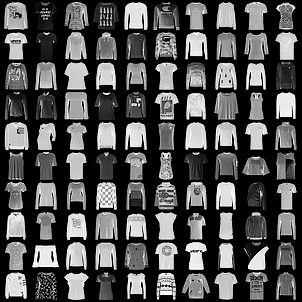

In [67]:
Image(f"generated_images_{mode}/epoch_-1.png") # real images

**(8)** (2 points) Briefly comment on what you observe, will Kocho be able to sell any of these hoodies/T-shirts? Play with the network parameter sizes and the other hyperparameters, all while keeping in mind the difficulties of min-max optimization you've analyzed in the previous notebook.

Alternatively, to enforce Lipschitzness, the projection/clipping steps can be replaced with **LMO-based** (Linear Minimization Oracle) update derived from the Frank-Wolfe/Conditional Gradient method (SCG for the discriminator, uSCG for the generator). This approach maintains a momentum-averaged gradient and is known as the [Scion optimizer](https://arxiv.org/pdf/2502.07529).
$$
\begin{aligned}
g_d^{k} &= \alpha_d \text{SG}_d(d^k, h^k) + (1-\alpha_d)\, g_d^{k-1},\\
g_h^{k} &= \alpha_g \text{SG}_h(d^k, h^k) + (1-\alpha_g)\, g_h^{k-1}.
\end{aligned}
$$

**Discriminator (SCG; constrained):**
$$
d^{k+1} \;=\; (1-\gamma_d)\, d^{k} \;+\; \gamma_d \,\operatorname{lmo}_{\|\cdot\|_{D}}\!\left(+\,g_d^{k}\right).
$$

**Generator (uSCG; unconstrained):**
$$
h^{k+1} \;=\; h^{k} \;+\; \gamma_h \,\operatorname{lmo}_{\|\cdot\|_{H}}\!\left(-\,g_h^{k}\right).
$$

Here $\operatorname{lmo}_{\|\cdot\|}$ is the linear minimization oracle over the unit ball of the chosen norm.
You can choose $\|\cdot\|_D$ and $\|\cdot\|_H$ independently from:
- **Spectral**: $\operatorname{lmo}(S) = -\,U V^\top$ (singular vectors of $S$).
- **Frobenius**: $\operatorname{lmo}(S) = - S / \|S\|_F$ (Normalized SGD).
- **Max ($l_\infty$)**: $\operatorname{lmo}(S) = -\operatorname{sign}(S)$.


**(9)** (3 points) Implement the helper lmo funtions for spectral, frobenius and sign norms. 

For `lmo_spectral`, by using SVD (Singular Value Decomposition), you should find the singular vectors, $U$ and $V$. The LMO direction for the spectral norm is $-UV^T$. Ensure the function correctly handles 2D (Linear) and 4D (Conv) tensors by unfolding the Conv weights. When dim(grad) < 2, you can use sign lmo instead.

In [68]:
def _svd(M):
    """Reduced SVD. On Apple GPUs (MPS) torch.linalg.svd is not implemented, so it is computed
    on the CPU and the factors are moved back to the original device. On CPU nothing changes."""
    if M.device.type == "mps":
        U, S, Vh = torch.linalg.svd(M.cpu(), full_matrices=False)
        return U.to(M.device), S.to(M.device), Vh.to(M.device)
    return torch.linalg.svd(M, full_matrices=False)

@torch.no_grad()
def lmo_spectral(grad):
    if grad.ndim == 2:  # Linear layer
        U, S, Vh = _svd(grad)          # reduced SVD: grad = U diag(S) Vh
        UVt = -(U @ Vh)                # lmo = -U V^T (all singular values set to 1)
        return UVt.view_as(grad)

    elif grad.ndim == 4:  # Conv or ConvTranspose
        # Reshape the grad: (out_c, in_c, kh, kw) -> (out_c, in_c * kh * kw)
        # (for ConvTranspose the first two dims are swapped, i.e. (in_c, out_c, kh, kw),
        #  but the same reshape/back-reshape is still consistent)
        out_c, in_c, kh, kw = grad.shape
        M = grad.reshape(out_c, in_c * kh * kw)
        U, S, Vh = _svd(M)
        UVt = -(U @ Vh)
        return UVt.reshape(out_c, in_c, kh, kw)

    else:  # anything else — use sign lmo
        return lmo_sign(grad)

@torch.no_grad()
def lmo_frobenius(grad):
    # -S / ||S||_F  (small eps avoids division by zero for an all-zero gradient)
    return -grad / (torch.linalg.norm(grad) + 1e-12)

@torch.no_grad()
def lmo_sign(grad):
    # -sign(S): vertex of the l_inf unit ball most aligned with -S
    return -torch.sign(grad)

def choose_lmo(grad, norm_choice="sign"):
    if norm_choice == "spectral":
        return lmo_spectral(grad)
    if norm_choice == "frobenius":
        return lmo_frobenius(grad)
    if norm_choice == "sign":
        return lmo_sign(grad)

In [69]:
# Sanity check for the LMOs on every parameter shape of the two networks.
# For lmo(S) = argmin_{||X|| <= 1} <S, X> we must have:
#   (a) same shape as S,  (b) ||lmo(S)|| = 1 (it lies on the boundary of the unit ball),
#   (c) <S, lmo(S)> = -||S||_*  (minus the DUAL norm: nuclear / Frobenius / l1),
#   (d) no random point of the unit ball gives a smaller <S, X>.
torch.manual_seed(0)

def _as_matrix(t):  # same unfolding used inside lmo_spectral
    return t.reshape(t.shape[0], -1)

def _norm(t, kind):  # primal norm of the unit ball
    if kind == "spectral":
        return torch.linalg.norm(_as_matrix(t), ord=2).item() if t.ndim >= 2 else t.abs().max().item()
    if kind == "frobenius":
        return torch.linalg.norm(t).item()
    return t.abs().max().item()

def _dual_norm(t, kind):
    if kind == "spectral":
        return torch.linalg.norm(_as_matrix(t), ord="nuc").item() if t.ndim >= 2 else t.abs().sum().item()
    if kind == "frobenius":
        return torch.linalg.norm(t).item()
    return t.abs().sum().item()

def _random_feasible(t, kind):  # random point on the unit sphere of the given norm
    X = torch.randn_like(t)
    return X / _norm(X, kind)

_shapes = sorted({tuple(p.shape) for p in list(Generator(100).parameters()) + list(DualVariable().parameters())},
                 key=len, reverse=True)
_ok = True
for kind in ["spectral", "frobenius", "sign"]:
    print(f"--- {kind} ---")
    for shape in _shapes:
        S = torch.randn(shape)
        L = choose_lmo(S, kind)
        inner = (S * L).sum().item()
        best_random = min((S * _random_feasible(S, kind)).sum().item() for _ in range(200))
        checks = [L.shape == S.shape,
                  abs(_norm(L, kind) - 1) < 1e-4,
                  abs(inner + _dual_norm(S, kind)) < 1e-3 * max(1, _dual_norm(S, kind)),
                  inner <= best_random + 1e-6]
        _ok &= all(checks)
        print(f"  {str(shape):<22} ||lmo|| = {_norm(L, kind):.4f}   <S,lmo> = {inner:10.3f}"
              f"   -||S||_* = {-_dual_norm(S, kind):10.3f}   best random = {best_random:10.3f}   {'OK' if all(checks) else 'FAIL'}")
print("\nall checks passed:", _ok)

--- spectral ---
  (100, 256, 3, 3)       ||lmo|| = 1.0000   <S,lmo> =  -4774.149   -||S||_* =  -4774.149   best random =    -20.843   OK
  (64, 1, 4, 4)          ||lmo|| = 1.0000   <S,lmo> =   -125.138   -||S||_* =   -125.138   best random =     -9.495   OK
  (256, 128, 3, 3)       ||lmo|| = 1.0000   <S,lmo> =  -8429.286   -||S||_* =  -8429.287   best random =    -27.572   OK
  (128, 64, 4, 4)        ||lmo|| = 1.0000   <S,lmo> =  -4024.755   -||S||_* =  -4024.755   best random =    -20.777   OK
  (1, 6272)              ||lmo|| = 1.0000   <S,lmo> =    -78.209   -||S||_* =    -78.209   best random =     -2.498   OK
  (256,)                 ||lmo|| = 1.0000   <S,lmo> =   -209.573   -||S||_* =   -209.573   best random =    -14.148   OK
  (1,)                   ||lmo|| = 1.0000   <S,lmo> =     -0.537   -||S||_* =     -0.537   best random =     -0.537   OK
  (64,)                  ||lmo|| = 1.0000   <S,lmo> =    -52.522   -||S||_* =    -52.522   best random =    -11.141   OK
  (128,)       

**(10)** (3 points) Now, implement the `step` method for the `SCION` optimizer class. 

In [70]:
from torch.optim.optimizer import Optimizer

class SCION(Optimizer):
    def __init__(self, params, lr=1e-3, momentum=1.0, norm: str='sign', scale=1.0, constrained=False):
        if norm not in {"spectral","frobenius","sign"}:
            raise ValueError("norm must be one of {'spectral','frobenius','sign'}")
        defaults = dict(lr=lr, momentum=momentum, scale=scale, constrained=constrained, norm=norm)
        super().__init__(params, defaults)

    @torch.no_grad()
    def step(self):
        for group in self.param_groups:
            lr = group['lr']
            momentum = group['momentum']
            constrained = group['constrained']
            norm = group['norm']
            scale = group['scale']

            for p in group['params']:
                g = p.grad
                if g is None:
                    continue
                state = self.state[p]

                if momentum != 1:
                    if 'momentum_buffer' not in state.keys():
                        state['momentum_buffer'] = torch.zeros_like(g)
                    buf = state['momentum_buffer']
                    # g^k = alpha * SG^k + (1 - alpha) * g^{k-1},  with alpha = momentum
                    buf.mul_(1 - momentum).add_(g, alpha=momentum) #FILL
                    lmo_input = buf 
                else:
                    lmo_input = g

                # lmo over the unit ball of the chosen norm (a descent direction for p.grad)
                direction = choose_lmo(lmo_input, norm) #FILL
                # the ball has radius `scale`: rho * lmo(.) is a point on its boundary
                update = scale * direction
                if constrained:
                    # SCG (Frank-Wolfe): p <- (1 - lr) * p + lr * scale * lmo(g)
                    # convex combination of p and a point of the ball -> p stays in the ball
                    p.data.mul_(1 - lr) # FILL

                # uSCG: p <- p + lr * scale * lmo(g)   (constrained: completes the convex combination)
                p.data.add_(update, alpha=lr) # FILL 

In [71]:
# Sanity check for SCION
torch.manual_seed(0)
_lr, _alpha, _scale = 2**-6, 0.9, 5.0

# 1) one step reproduces the formulas exactly (momentum buffer, constrained and unconstrained update)
for _constrained in [False, True]:
    _w = nn.Parameter(torch.randn(8, 6))
    _opt = SCION([_w], lr=_lr, momentum=_alpha, norm="spectral", scale=_scale, constrained=_constrained)
    _buf, _w_ref = torch.zeros(8, 6), _w.detach().clone()
    for _ in range(3):
        _w.grad = torch.randn(8, 6)
        _buf = _alpha * _w.grad + (1 - _alpha) * _buf
        _w_ref = (1 - _lr) * _w_ref if _constrained else _w_ref
        _w_ref = _w_ref + _lr * _scale * lmo_spectral(_buf)
        _opt.step()
    print(f"constrained={_constrained!s:<5}  max |w - w_ref| = {(_w - _w_ref).abs().max():.2e}")

# 2) constrained (SCG) vs unconstrained (uSCG) under a CONSTANT gradient, i.e. always pushed in the
#    same direction (worst case): SCG converges to the boundary point scale * lmo(G) and never
#    leaves the ball of radius `scale`; uSCG keeps moving and its norm grows linearly.
print()
for _norm_name in ["sign", "spectral", "frobenius"]:
    _G = torch.randn(16, 32)
    for _constrained in [True, False]:
        _w = nn.Parameter(torch.zeros(16, 32))
        _opt = SCION([_w], lr=_lr, momentum=_alpha, norm=_norm_name, scale=_scale, constrained=_constrained)
        _max_norm = 0.0
        for _ in range(1000):
            _w.grad = _G + 0.1 * torch.randn_like(_G)
            _opt.step()
            _max_norm = max(_max_norm, _norm(_w.detach(), _norm_name))
        print(f"{'SCG ' if _constrained else 'uSCG'} {_norm_name:<9} max ||w|| over 1000 steps = {_max_norm:8.4f}"
              f"   (ball radius = {_scale})")

# 3) it actually minimises: least squares  min_W ||W X - Y||^2 with the unconstrained (uSCG) variant
print()
_X, _Wt = torch.randn(20, 100), torch.randn(10, 20)
_Y = _Wt @ _X
_W = nn.Parameter(torch.zeros(10, 20))
_opt = SCION([_W], lr=1e-2, momentum=_alpha, norm="spectral", scale=1.0)
for _k in range(301):
    _opt.zero_grad()
    _loss = ((_W @ _X - _Y) ** 2).mean()
    _loss.backward()
    _opt.step()
    if _k % 100 == 0:
        print(f"uSCG least squares, step {_k:3d}: loss = {_loss.item():.4f}")

constrained=False  max |w - w_ref| = 1.19e-07
constrained=True   max |w - w_ref| = 5.96e-08

SCG  sign      max ||w|| over 1000 steps =   5.0000   (ball radius = 5.0)
uSCG sign      max ||w|| over 1000 steps =  78.1250   (ball radius = 5.0)
SCG  spectral  max ||w|| over 1000 steps =   4.9921   (ball radius = 5.0)
uSCG spectral  max ||w|| over 1000 steps =  77.9968   (ball radius = 5.0)
SCG  frobenius max ||w|| over 1000 steps =   4.9794   (ball radius = 5.0)
uSCG frobenius max ||w|| over 1000 steps =  77.7974   (ball radius = 5.0)

uSCG least squares, step   0: loss = 14.2523
uSCG least squares, step 100: loss = 8.1208
uSCG least squares, step 200: loss = 4.1375
uSCG least squares, step 300: loss = 1.9169


**(11)** (2 points) Implement an the alternating gradient ascent/descent update for the `SCION` optimizer. 

**Hints**: Thanks to lmo based updates of `SCION`, it is no longer necessary to enforce Lipschitzness.

In [72]:
def alternating_update_scion(step_k, d, g, d_optim, g_optim, noise_samples, real_samples, d_ratio=2):
    # clear old gradients of BOTH networks (backward() always reaches the parameters of d and g)
    d_optim.zero_grad()
    g_optim.zero_grad()

    if step_k % d_ratio != 0:
        # dual (discriminator) step: ASCENT on the objective. SCION, like every torch optimizer,
        # moves along a descent direction of p.grad (lmo(grad)), so we backpropagate -objective.
        obj = objective(d, g, real_samples, noise_samples)
        (-obj).backward()
        d_optim.step()
        # no d.enforce_lipschitz(): the constrained SCG update (convex combination with a point
        # of the norm ball of radius `scale`) keeps the dual parameters inside the ball by itself
    else:
        # generator step: DESCENT on the objective (computed with the updated d^{k+1})
        obj = objective(d, g, real_samples, noise_samples)
        obj.backward()
        g_optim.step()

    return obj.item()

With all the ingredients in hand, we can train Kocho's WGAN with SCION now.

The following cell defines the two networks.

In [73]:
n_epochs = 20 # How many passes over the digit image dataset
noise_dim = 100 # Noise dimension for the generator
mode = "scion"

# Apple-silicon GPU (MPS) if available, otherwise CPU
device = "mps" if torch.backends.mps.is_available() else "cpu"
print("device:", device)
d = DualVariable(mode=mode).to(device)
g = Generator(noise_dim=noise_dim).to(device)

d_constrained = True  # SCG: the dual variable must stay in the norm ball (Lipschitz constraint)
g_constrained = False # uSCG: the generator is unconstrained

device: mps


We recommend the following hyperparameters to start with.

In [74]:
norm_d = "sign"
norm_g = "spectral"
lr = 2**-6
alpha = 0.9
scale = 5.0

Define `SCION` optimizers.

In [75]:
d_optim = SCION(d.parameters(), lr=lr, momentum=alpha, norm=norm_d, scale=scale, constrained=d_constrained)
g_optim = SCION(g.parameters(), lr=lr, momentum=alpha, norm=norm_g, scale=scale, constrained=g_constrained)

The following cell runs the training loop, this might take a few minutes.

In [76]:
train(d, g, d_optim, g_optim, alternating_update_scion, device=device,
      n_epochs=n_epochs, num_test_samples=100, noise_dim=noise_dim, f_ratio=2, mode=mode)

Epoch:   0%|          | 0/20 [00:00<?, ?it/s]

Batch:   0%|          | 0/188 [00:00<?, ?it/s]

Batch:   0%|          | 0/188 [00:00<?, ?it/s]

Batch:   0%|          | 0/188 [00:00<?, ?it/s]

Batch:   0%|          | 0/188 [00:00<?, ?it/s]

Batch:   0%|          | 0/188 [00:00<?, ?it/s]

... (11 outputs left out)

Batch:   0%|          | 0/188 [00:00<?, ?it/s]

Batch:   0%|          | 0/188 [00:00<?, ?it/s]

Batch:   0%|          | 0/188 [00:00<?, ?it/s]

Batch:   0%|          | 0/188 [00:00<?, ?it/s]

In [77]:
# Save the networks trained with SCION (+ optimizer states and hyperparameters) to disk
import os
os.makedirs("checkpoints", exist_ok=True)
ckpt_path_scion = f"checkpoints/{mode}_d-{norm_d}_g-{norm_g}_lr{lr:g}_scale{scale:g}_epochs{n_epochs}.pt"
torch.save({
    "d": d.state_dict(), "g": g.state_dict(),
    "d_optim": d_optim.state_dict(), "g_optim": g_optim.state_dict(),
    "hparams": dict(mode=mode, n_epochs=n_epochs, noise_dim=noise_dim, norm_d=norm_d, norm_g=norm_g,
                    lr=lr, alpha=alpha, scale=scale, d_constrained=d_constrained,
                    g_constrained=g_constrained, f_ratio=2, device=device),
}, ckpt_path_scion)
print("saved:", ckpt_path_scion)

# To reload later (works on CPU or GPU thanks to map_location):
# ckpt = torch.load(ckpt_path_scion, map_location=device)
# d = DualVariable(mode="scion").to(device);                           d.load_state_dict(ckpt["d"])
# g = Generator(noise_dim=ckpt["hparams"]["noise_dim"]).to(device);    g.load_state_dict(ckpt["g"])

saved: checkpoints/scion_d-sign_g-spectral_lr0.015625_scale5_epochs20.pt


Once the training is complete, you can visualize the training process in the following cell. Use the slider to scroll through generated image collages from every epoch.

In [ ]:
def show_image(epoch):
    return Image(f"generated_images_{mode}/epoch_{epoch}.png")
interact(show_image, epoch=SelectionSlider(
    options=range(n_epochs),
    value=0,
    description="Epoch:",
    disabled=False,
    continuous_update=False,
    orientation="horizontal",
    readout=True
))

interactive(children=(SelectionSlider(continuous_update=False, description='Epoch:', options=(0, 1, 2, 3, 4, 5…

<function __main__.show_image(epoch)>

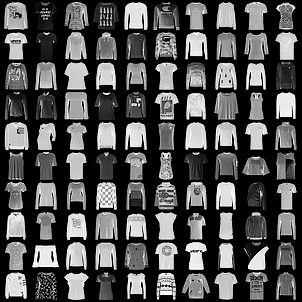

In [79]:
Image(f"generated_images_{mode}/epoch_-1.png") # real images